# Notebook 1 — Read text, tables, and figures


## Set up

Start Ollama with `qwen3.5:4b` and `qwen3-embedding:4b` available. If `corpus/pdf` is empty, run `python download_corpus.py` from this folder.

PyMuPDF may suggest installing `pymupdf_layout`. The cells here use PyMuPDF's built-in `find_tables()`.


In [1]:
from pathlib import Path
import sys

HERE = Path.cwd().resolve()
if not (HERE / "document_rag.py").exists():
    raise SystemExit("Set the notebook's working directory to 16_agentic_document_rag.")
sys.path.insert(0, str(HERE))

import document_rag as desk

print("Ollama:", "up" if desk.ollama_alive() else "DOWN — start Ollama")
print("PDFs:", sorted(p.name for p in (desk.PDF_DIR).glob("*.pdf")))
print("DOCX:", sorted(p.name for p in (desk.DOCX_DIR).glob("*.docx")))


Ollama: up
PDFs: ['0082969.pdf', '1295982.pdf', '1659677.pdf', '2025833.pdf', '6002966.pdf', '6838482.pdf', '7257900.pdf']
DOCX: ['walker_ranch_seismic.docx']


## 1. Find a value missing from the PDF text

Open page 7 of `7257900.pdf` and find the Commercial Real Estate row in Table 5. Run the cell and look for its **5.4%** portfolio loss rate in the extracted text. The table is stored as an image, so `page.get_text()` misses the rate.

The paragraph on that page says Commercial Real Estate accounts for **22% of total losses**. Check which of these two numbers answers the question before you index the page.


In [2]:
import fitz

pdf = desk.PDF_DIR / "7257900.pdf"
with fitz.open(pdf) as doc:
    page = doc[6]  # fitz counts from 0, so index 6 is page 7
    text = page.get_text("text") or ""  # the text layer only; pixels are invisible here

print("chars on page 7:", len(text.strip()))
print("5.4% in the text layer:", "5.4%" in text)
print("Commercial Real Estate in the text layer:", "Commercial Real Estate" in text)
print()
print(text[:700])


chars on page 7: 2106
5.4% in the text layer: False
Commercial Real Estate in the text layer: True

PNC 2017 Mid-Cycle Stress Test Disclosures - 7 
 
 
 
In the hypothetical severely adverse scenario, depressed earnings, losses and provision, and the capital 
actions assumed to occur reduce projected regulatory capital.  The loan loss estimates in Table 5 represent 
estimates of the net charge-off activity recorded during the nine-quarter stress period.  Wholesale Loans 
(Commercial and Industrial (“C&I”), Commercial Real Estate (“CRE”), and Other Loans) account for 62% of 
total losses, with 40% of losses originating from C&I/Other Loans and 22% from CRE.  Of the remaining 
total losses, approximately $1.5 billion, or 20% of total losses, are from Residential Real Estate (First and 
Junio


## 2. Check what the table detector found

`page.find_tables()` can pick up bar-chart axes as grids. `table_is_useful` drops grids made of percentages alone. Run the cell and look at the vendor price table that passed the filter. `markdown_table` keeps its headings and values together.

A second run can reuse the saved page images.


In [3]:
elements = desk.parse_corpus()
# Chart pages and picture-tables become a second element, type "figure".
# Cached captions are reused, so this cell does not call the vision model again.
elements = desk.attach_captions(elements)
print(desk.corpus_summary(elements))

print("\n--- a price table the filter kept ---")
for element in elements:
    if element["element_type"] == "table" and "Price Per Call" in element["text"]:
        print(element["doc_id"], "page", element["page"])
        print(element["text"][:700])
        break


parsing 0082969.pdf


Consider using the pymupdf_layout package for a greatly improved page layout analysis.


parsing 1295982.pdf


parsing 1659677.pdf


parsing 2025833.pdf


parsing 6002966.pdf


parsing 6838482.pdf


parsing 7257900.pdf


parsing walker_ranch_seismic.docx


{'documents': 8, 'elements': 76, 'by_type': {'text': 61, 'table': 8, 'figure': 7}}

--- a price table the filter kept ---
6838482 page 3
| Vendors |  | Current Price Per Call |  | Proposed Price Per Call |
| --- | --- | --- | --- | --- |
|  |  | (range depends on |  | (range depends on monthly |
|  |  | monthly volume) |  | volume) |
| Y&Y Holdings, LLC (“Agility Marketing”) | $5.21 - $5.50 | $5.21 - $5.50 | $8.90 - $9.40 | $8.90 - $9.40 |
| Faneuil, INC | $4.55 - $5.07 |  | $10.60 - $11.25 |  |


## 3. Read the chart as an image

On page 3 of `1659677.pdf`, the text layer gives the category names and percentages in separate lists. Run the cell and compare the caption with the page image. Qwen pairs each category with its percentage.

```text
U.S. Large | 128%
EAFE | 164%
U.S. Bonds | -33%
TIPS | 7%
Commodities | -55%
EM Equity | -83%
```

The caption gives keyword and vector search text to match. Check any value you cite against the image. An earlier model caption for PNC page 7 returned `1.7 | 5.4%` and left out the row name. The checked copy in `caption_overrides.json` keeps Commercial Real Estate attached to those values.


Figure in 1659677.pdf, page 3. Media Contact.
Here are the transcribed tables and charts from your document:


---

### **Figure 1**  
```
U.S. Large | 128%
EAFE | 164%
U.S. Bonds | -33%
TIPS | 7%
Commodities | -55%
EM Equity | -83%
```


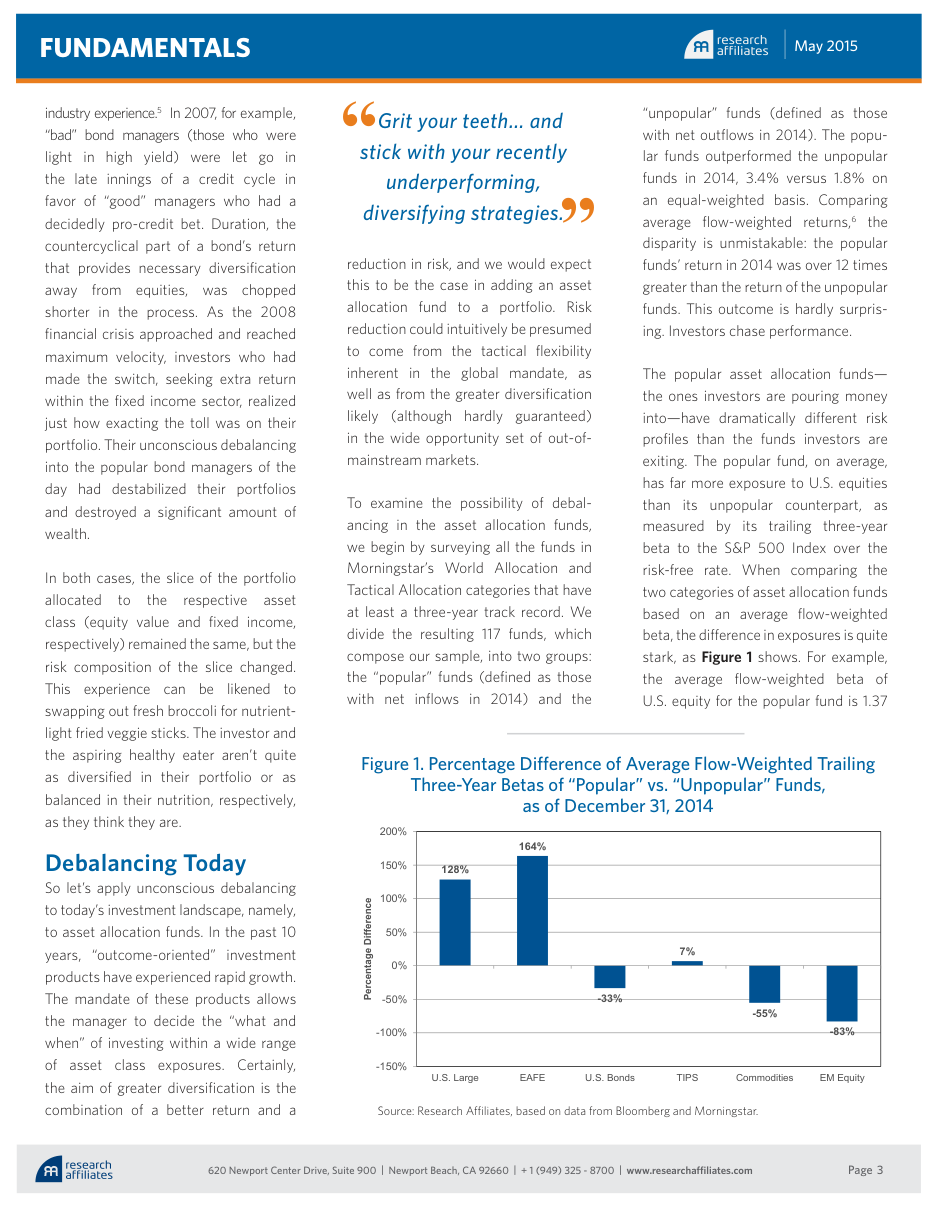

In [4]:
from IPython.display import Image, display

for element in elements:
    if element["doc_id"] == "1659677" and element["element_type"] == "figure":
        print(element["text"])
        display(Image(filename=str(HERE / element["page_image"])))
        break


## 4. Read the Word file

`walker_ranch_seismic.docx` has paragraphs and three embedded images. The lab stores the Word elements as page 1 and shows each image separately.

Find the paragraph that describes the red dots as micro-earthquakes. An earlier vision pass described them as red triangles. For this question, the paragraph supplies the evidence you need.


In [5]:
docx_elements = [e for e in elements if e["doc_id"] == "walker_ranch_seismic"]
for element in docx_elements:
    print(f"\n## {element['element_type']}  image={element['page_image'] or '(none)'}")
    print(element["text"][:500])



## text  image=corpus/pages/walker_ranch_seismic/figure_1.png
Walker Ranch seismic images

Project: Identifying High Potential Well Targets with 3D Seismic and Mineralogy,

2015-2016. Data attribute analysis funded by DOE Geothermal Technologies Office.

PI: R. Mellors

Collaborators: Lawrence Livermore National Laboratory, Optim, Inc, and Agua Caliente.

Note: Data collection and processing funded by Agua Caliente. Original data remains property of Agua Caliente.

Data from a study examining the use of the seismic attributes to identify zones of high perm

## figure  image=corpus/pages/walker_ranch_seismic/figure_1.png
Embedded figure in walker_ranch_seismic.docx. Use the paragraphs in this same file for the caption. Do not invent labels for the picture.

## figure  image=corpus/pages/walker_ranch_seismic/figure_2.png
Embedded figure in walker_ranch_seismic.docx. Use the paragraphs in this same file for the caption. Do not invent labels for the picture.

## figure  image=corpus/pages

## Exercise

`18,443.87` is a real amount in the Town of Newton minutes (`2025833`).

1. Which `doc_id`, page, and `element_type` contain that amount?
2. Why is that element text, not table, even though the benchmark calls the question `table_required`?

<details><summary>Answer — open after the search</summary>

1. `2025833`, page 6, `text`. The minutes were extracted as prose. The number survived `get_text()`.
2. `table_required` describes the page a reviewer looked at. It does not mean `find_tables()` returned a clean grid. The index stores the channel that actually contains the digits.

</details>


In [6]:
for element in elements:
    if "18,443.87" in element["text"]:
        print(element["doc_id"], "page", element["page"], element["element_type"])


2025833 page 6 text
